<a href="https://colab.research.google.com/github/Laisakamisli/PDS/blob/main/09_Regresi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nur Laisa Kamisli Syai  
250907500021  
  
Link tugas sebelumnya [PDS Laisa](https://colab.research.google.com/drive/1MTkK3M1b4QTcW8cyVgyy9ai5V6yh709Y?usp=sharing) [Docs](https://docs.google.com/document/d/1u15Ep0E0JRrbEzN7wmfHjzq29Qxd_axbnHXc9qHToxQ/edit?usp=sharing)

#Regresi

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

data = {
    "partisipan": np.arange(1, 11),
    "kopi": [2, 3, 1, 4, 2, 5, 3, 6, 4, 5],
    "gula": [10, 15, 12, 18, 14, 20, 16, 25, 22, 24]
}

df = pd.DataFrame(data)

x = df[['kopi']]
y = df['gula']

x = sm.add_constant(x)

model = sm.OLS(y,x)
result = model.fit()

print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                   gula   R-squared:                       0.858
Model:                            OLS   Adj. R-squared:                  0.841
Method:                 Least Squares   F-statistic:                     48.53
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           0.000116
Time:                        03:46:42   Log-Likelihood:                -20.142
No. Observations:                  10   AIC:                             44.28
Df Residuals:                       8   BIC:                             44.89
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.1778      1.628      4.410      0.0

interpretasi?

97 Kota: [Github](https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv)  
Kota Yogyakarta

In [ ]:
import pandas as pd

# 1. Memuat dataset dari link GitHub
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

# 2. Filter data khusus untuk "Kota Yogyakarta"
kolom_wilayah = 'Yogyakarta' if 'Yogyakarta' in df.columns else 'Kota'

df_yogyakarta = df[df[kolom_wilayah].str.contains('Yogyakarta', case=False, na=False)]

# 3. Memilih kolom spesifik (variabel bebas dan dependen)
kolom_pilihan = [kolom_wilayah,'Tahun','bm_ekonomi', 'bm_infrastruktur', 'DBH_PAJAK', 'KEMISKINAN']

# Jika ingin menyertakan nama daerah/tahun agar tahu baris miliknya, Anda bisa menambahkannya di list:
# kolom_pilihan = [kolom_wilayah, 'bm_ekonomi', 'bm_infrastruktur', 'DBH_Pajak', 'Kemiskinan']

df_subset = df_yogyakarta[kolom_pilihan]

# 4. Menampilkan baris dan kolom
print("--- TAMPILAN KESELURUHAN DATA KOTA YOGYAKARTA ---")
print(df_subset)

# Alternatif: Menampilkan beberapa baris pertama saja (misal 5 baris awal)
print("\n--- 5 BARIS PERTAMA ---")
print(df_subset.head())

# Menampilkan jumlah baris dan kolom (Shape)
print(f"\nJumlah baris dan kolom: {df_subset.shape}")

--- TAMPILAN KESELURUHAN DATA KOTA YOGYAKARTA ---
                Kota  Tahun  bm_ekonomi  bm_infrastruktur  DBH_PAJAK  \
517  Kota Yogyakarta   2014      144.22            262.90      72.61   
518  Kota Yogyakarta   2015      268.98            265.95      90.18   
519  Kota Yogyakarta   2016      276.32            151.69     137.51   
520  Kota Yogyakarta   2017      173.24            240.59      96.22   
521  Kota Yogyakarta   2018      132.54             85.97     155.29   
522  Kota Yogyakarta   2019       76.70             52.15     103.48   
523  Kota Yogyakarta   2020      288.35             54.99     133.72   
524  Kota Yogyakarta   2021       65.06            196.65     145.77   
525  Kota Yogyakarta   2022      124.41            163.85     160.26   
526  Kota Yogyakarta   2023      124.52            179.50     114.48   
527  Kota Yogyakarta   2024      130.10             51.87     116.60   

     KEMISKINAN  
517       19.84  
518        9.55  
519       11.50  
520       18.

In [ ]:
# Import Library
import numpy as np
import pandas as pd
import statsmodels.api as sm

# 1. Memuat dataset dari link GitHub
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

# (Opsional) Jika dataset berisi data gabungan beberapa daerah/kabupaten/kota,
# Anda dapat memfilter khusus untuk Kota Yogyakarta terlebih dahulu.
# Sesuaikan nama kolom wilayah pada dataset Anda (misal: 'kabupaten_kota', 'daerah', atau 'wilayah').
# Contoh:
# df_yogya = df[df['kabupaten_kota'].str.contains('Yogyakarta', case=False, na=False)]
# Jika data pada link sudah khusus Kota Yogyakarta, Anda bisa langsung menggunakan `df`.

# 2. Memisahkan variabel independen (X) dan dependen (y)
X = df[['bm_ekonomi', 'bm_infrastruktur', 'DBH_PAJAK']]
y = df['KEMISKINAN']

# Menangani nilai yang hilang (missing values) jika ada pada data
data_reg = pd.concat([X, y], axis=1).dropna()
X = data_reg[['bm_ekonomi', 'bm_infrastruktur', 'DBH_PAJAK']]
y = data_reg['KEMISKINAN']

# 3. Menambahkan kolom konstanta untuk intercept
X = sm.add_constant(X)

# 4. Membangun model regresi OLS (Ordinary Least Squares)
model = sm.OLS(y, X)
results = model.fit()

# 5. Menampilkan hasil ringkasan regresi
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:             KEMISKINAN   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.002
Method:                 Least Squares   F-statistic:                    0.2556
Date:                Thu, 15 Oct 2026   Prob (F-statistic):              0.857
Time:                        03:46:42   Log-Likelihood:                -3059.1
No. Observations:                1067   AIC:                             6126.
Df Residuals:                    1063   BIC:                             6146.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               12.7467      0.533  

# 3D

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import plotly.graph_objects as go

# 1. Memuat dataset dari link GitHub
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

# 2. Filter data khusus untuk "Kota Yogyakarta"
# Menyesuaikan dengan kolom nama daerah yang ada di dataset
kolom_wilayah = 'Yogyakarta' if 'Yogyakarta' in df.columns else 'Kota'
df_yogyakarta = df[df[kolom_wilayah].str.contains('Yogyakarta', case=False, na=False)].copy()

# 3. Memilih Variabel Independen & Dependen
# X1: bm_ekonomi, X2: bm_infrastruktur, X3: DBH_Pajak
# Y: Kemiskinan
X = df_yogyakarta[['bm_ekonomi', 'bm_infrastruktur', 'DBH_PAJAK']]
y = df_yogyakarta['KEMISKINAN']

# Membersihkan data dari missing values (jika ada)
data_regresi = pd.concat([X, y], axis=1).dropna()
X_clean = data_regresi[['bm_ekonomi', 'bm_infrastruktur', 'DBH_PAJAK']]
y_clean = data_regresi['KEMISKINAN']

# 4. MENAMBAHKAN INTERCEPT
X_model = sm.add_constant(X_clean)

# 5. ESTIMASI MODEL OLS
model = sm.OLS(y_clean, X_model)
results = model.fit()

# 6. MENAMPILKAN RINGKASAN HASIL REGRESI
print("\n")
print("=" * 70)
print(" HASIL REGRESI LINEAR BERGANDA - KOTA YOGYAKARTA")
print("=" * 70)
print(results.summary())

# 7. MENGAMBIL KOEFISIEN REGRESI
intercept = results.params["const"]
coef_ekonomi = results.params["bm_ekonomi"]
coef_infrastruktur = results.params["bm_infrastruktur"]
coef_dbh = results.params["DBH_PAJAK"]
r_squared = results.rsquared
adjusted_r_squared = results.rsquared_adj

# 8. MEMBUAT PERSAMAAN REGRESI
persamaan = (
    f"Ŷ = {intercept:.3f}"
    f" + ({coef_ekonomi:.3f}) X1"
    f" + ({coef_infrastruktur:.3f}) X2"
    f" + ({coef_dbh:.3f}) X3"
)
print("\n")
print("=" * 70)
print(" PERSAMAAN REGRESI")
print("=" * 70)
print(persamaan)
print(f"\nR2 = {r_squared:.4f}")
print(f"Adjusted R2 = {adjusted_r_squared:.4f}")

# 9. MENGHITUNG NILAI PREDIKSI
data_regresi["Prediksi"] = results.predict(X_model)
print("\n")
print("=" * 70)
print(" DATA AKTUAL & PREDIKSI KEMISKINAN")
print("=" * 70)
print(
    data_regresi[["bm_ekonomi", "bm_infrastruktur", "DBH_PAJAK", "KEMISKINAN", "Prediksi"]]
    .round(2)
)

# 10. MEMBUAT GRID UNTUK BIDANG REGRESI 3D (Menggunakan 2 Variabel Utama untuk Visualisasi)
x1 = np.linspace(
    data_regresi["bm_ekonomi"].min(),
    data_regresi["bm_ekonomi"].max(),
    40
)
x2 = np.linspace(
    data_regresi["bm_infrastruktur"].min(),
    data_regresi["bm_infrastruktur"].max(),
    40
)
X1, X2 = np.meshgrid(x1, x2)

# Menggunakan rata-rata nilai DBH_Pajak (X3) untuk bidang proyeksi 3D
mean_dbh = data_regresi["DBH_PAJAK"].mean()

# 11. MENGHITUNG NILAI Y PADA BIDANG REGRESI
Y = (intercept + coef_ekonomi * X1 + coef_infrastruktur * X2 + coef_dbh * mean_dbh)

# 12. MEMBUAT FIGURE 3D
fig = go.Figure()

# 13. MENAMPILKAN DATA AKTUAL
fig.add_trace(
    go.Scatter3d(
        x=data_regresi["bm_ekonomi"],
        y=data_regresi["bm_infrastruktur"],
        z=data_regresi["KEMISKINAN"],
        mode="markers",
        marker=dict(
            size=7,
            color="red",
            opacity=0.9
        ),
        name="Data Aktual",
        hovertemplate=(
            "BM Ekonomi: %{x}<br>"
            "BM Infrastruktur: %{y}<br>"
            "Kemiskinan: %{z}"
            "<extra></extra>"
        )
    )
)

# 14. MENAMPILKAN BIDANG REGRESI
fig.add_trace(
    go.Surface(
        x=X1, y=X2, z=Y,
        opacity=0.60,
        colorscale="Viridis",
        name="Regression Plane",
        hovertemplate=(
            "BM Ekonomi: %{x:.2f}<br>"
            "BM Infrastruktur: %{y:.2f}<br>"
            "Prediksi Kemiskinan: %{z:.2f}"
            "<extra></extra>"
        )
    )
)

# 15. MENGATUR TAMPILAN GRAFIK
fig.update_layout(
    title={
        "text": (
            "REGRESI LINEAR BERGANDA 3D (KOTA YOGYAKARTA)"
            "<br>"
            f"<sup>{persamaan} | R2 = {r_squared:.3f}</sup>"
        ),
        "x": 0.5
    },
    scene={
        "xaxis": {"title": "BM Ekonomi (X1)"},
        "yaxis": {"title": "BM Infrastruktur (X2)"},
        "zaxis": {"title": "Kemiskinan (Y)"}
    },
    width=1000,
    height=750,
    margin={"l": 0, "r": 0, "b": 0, "t": 100},
    legend={"x": 0.02, "y": 0.98}
)

# 16. MENAMPILKAN GRAFIK
fig.show()



 HASIL REGRESI LINEAR BERGANDA - KOTA YOGYAKARTA
                            OLS Regression Results                            
Dep. Variable:             KEMISKINAN   R-squared:                       0.117
Model:                            OLS   Adj. R-squared:                 -0.261
Method:                 Least Squares   F-statistic:                    0.3098
Date:                Thu, 15 Oct 2026   Prob (F-statistic):              0.818
Time:                        03:46:42   Log-Likelihood:                -31.849
No. Observations:                  11   AIC:                             71.70
Df Residuals:                       7   BIC:                             73.29
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

# Uji Normalitas

 UJI NORMALITAS RESIDUAL (SHAPIRO-WILK TEST)
Statistik Hitung (W) : 0.8146
P-Value              : 0.0147
Kesimpulan           : Residual TIDAK berdistribusi normal (Tolak H0)


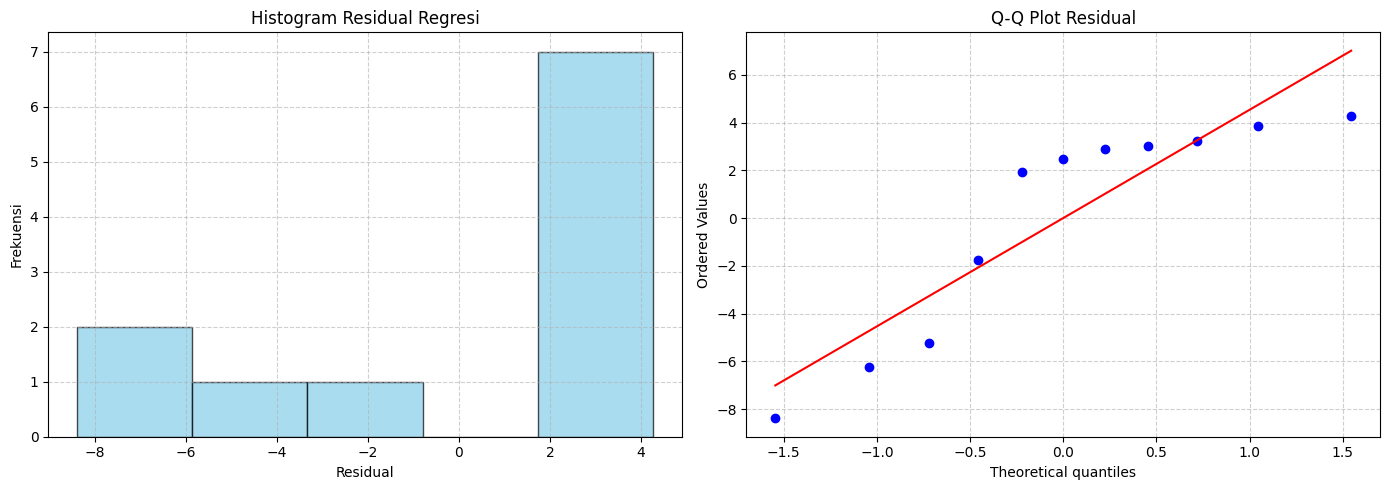

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. Memuat dataset dan melakukan regresi seperti sebelumnya
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

# Filter Kota Yogyakarta
kolom_wilayah = 'Yogyakarta' if 'Yogyakarta' in df.columns else 'Kota'
df_yogyakarta = df[df[kolom_wilayah].str.contains('Yogyakarta', case=False, na=False)].copy()

# Variabel X dan Y
X = df_yogyakarta[['bm_ekonomi', 'bm_infrastruktur', 'DBH_PAJAK']]
y = df_yogyakarta['KEMISKINAN']

# Bersihkan Missing Values
data_regresi = pd.concat([X, y], axis=1).dropna()
X_clean = data_regresi[['bm_ekonomi', 'bm_infrastruktur', 'DBH_PAJAK']]
y_clean = data_regresi['KEMISKINAN']

# Model OLS
X_model = sm.add_constant(X_clean)
model = sm.OLS(y_clean, X_model)
results = model.fit()

# 2. MENGAMBIL RESIDUAL DARI MODEL REGRESI
residual = results.resid

# 3. UJI STATISTIK NORMALITAS (Shapiro-Wilk Test)
# H0: Residual berdistribusi normal
# H1: Residual tidak berdistribusi normal
shapiro_stat, shapiro_p_value = stats.shapiro(residual)

print("=" * 70)
print(" UJI NORMALITAS RESIDUAL (SHAPIRO-WILK TEST)")
print("=" * 70)
print(f"Statistik Hitung (W) : {shapiro_stat:.4f}")
print(f"P-Value              : {shapiro_p_value:.4f}")

if shapiro_p_value > 0.05:
    print("Kesimpulan           : Residual berdistribusi normal (Gagal tolak H0)")
else:
    print("Kesimpulan           : Residual TIDAK berdistribusi normal (Tolak H0)")
print("=" * 70)


# 4. VISUALISASI UJI NORMALITAS (Histogram & Q-Q Plot)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Histogram Residual
axes[0].hist(residual, bins='auto', edgecolor='black', alpha=0.7, color='skyblue')
axes[0].set_xlabel('Residual')
axes[0].set_ylabel('Frekuensi')
axes[0].set_title('Histogram Residual Regresi')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Q-Q Plot Residual
stats.probplot(residual, dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot Residual')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

 UJI ASUMSI KLASIK REGRESI LINEAR BERGANDA (KOTA YOGYAKARTA)

[1] UJI NORMALITAS (Shapiro-Wilk)
    - Statistik W : 0.8146
    - P-Value     : 0.0147
    -> Kesimpulan : Residual tidak berdistribusi normal


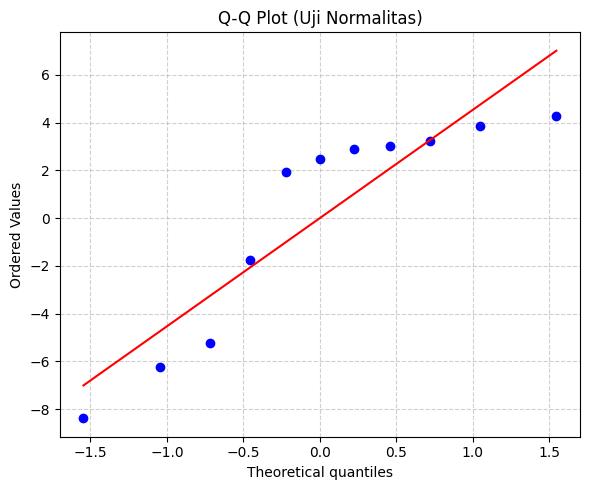

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.stats.diagnostic as smd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
import scipy.stats as stats
import matplotlib.pyplot as plt

# 1. MEMUAT DATASET DAN PERSIAPAN DATA KOTA YOGYAKARTA
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"
df = pd.read_csv(url)

# Filter khusus Kota Yogyakarta
kolom_wilayah = 'Yogyakarta' if 'Yogyakarta' in df.columns else 'Kota'
df_yogyakarta = df[df[kolom_wilayah].str.contains('Yogyakarta', case=False, na=False)].copy()

# Variabel Independen & Dependen
X = df_yogyakarta[['bm_ekonomi', 'bm_infrastruktur', 'DBH_PAJAK']]
y = df_yogyakarta['KEMISKINAN']

# Bersihkan Missing Values
data_regresi = pd.concat([X, y], axis=1).dropna()
X_clean = data_regresi[['bm_ekonomi', 'bm_infrastruktur', 'DBH_PAJAK']]
y_clean = data_regresi['KEMISKINAN']

# Tambahkan konstanta untuk OLS
X_model = sm.add_constant(X_clean)
model = sm.OLS(y_clean, X_model)
results = model.fit()

# Ambil Residual dan Prediksi
residual = results.resid
y_pred = results.fittedvalues

print("=" * 70)
print(" UJI ASUMSI KLASIK REGRESI LINEAR BERGANDA (KOTA YOGYAKARTA)")
print("=" * 70)


# ==========================================
# 1. UJI NORMALITAS (Shapiro-Wilk Test)
# ==========================================
shapiro_stat, shapiro_p = stats.shapiro(residual)
print("\n[1] UJI NORMALITAS (Shapiro-Wilk)")
print(f"    - Statistik W : {shapiro_stat:.4f}")
print(f"    - P-Value     : {shapiro_p:.4f}")
if shapiro_p > 0.05:
    print("    -> Kesimpulan : Residual berdistribusi normal (Asumsi Terpenuhi)")
else:
    print("    -> Kesimpulan : Residual tidak berdistribusi normal")

# VISUALISASI
fig, ax = plt.subplots(figsize=(6, 5))
# 1. Q-Q Plot (Normalitas)
stats.probplot(residual, dist="norm", plot=ax)
ax.set_title("Q-Q Plot (Uji Normalitas)")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# Uji Multikolinearitas


[2] UJI MULTIKOLINEARITAS (Variance Inflation Factor)
        Variabel      VIF
      bm_ekonomi 1.013995
bm_infrastruktur 1.279428
       DBH_PAJAK 1.278753
    -> Variabel bm_ekonomi bebas dari multikolinearitas (VIF < 10)
    -> Variabel bm_infrastruktur bebas dari multikolinearitas (VIF < 10)
    -> Variabel DBH_PAJAK bebas dari multikolinearitas (VIF < 10)


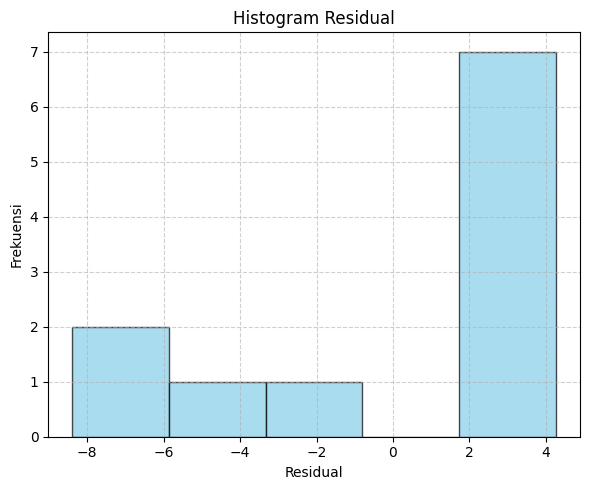

In [ ]:
# ==========================================
# 2. UJI MULTIKOLINEARITAS (VIF)
# ==========================================
print("\n[2] UJI MULTIKOLINEARITAS (Variance Inflation Factor)")
vif_data = pd.DataFrame()
vif_data["Variabel"] = X_clean.columns
vif_data["VIF"] = [variance_inflation_factor(X_clean.values, i) for i in range(X_clean.shape[1])]
print(vif_data.to_string(index=False))
for idx, row in vif_data.iterrows():
    if row["VIF"] < 10:
        print(f"    -> Variabel {row['Variabel']} bebas dari multikolinearitas (VIF < 10)")
    else:
        print(f"    -> Variabel {row['Variabel']} terindikasi multikolinearitas (VIF >= 10)")

# 2. Histogram Residual (Normalitas)
fig, ax = plt.subplots(figsize=(6, 5))
ax.hist(residual, bins='auto', edgecolor='black', alpha=0.7, color='skyblue')
ax.set_title("Histogram Residual")
ax.set_xlabel("Residual")
ax.set_ylabel("Frekuensi")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# Uji Autokorelasi


[3] UJI AUTOKORELASI (Durbin-Watson)
    - Nilai D-W   : 2.5679
    -> Catatan    : Nilai sekitar 2 umumnya menandakan tidak ada autokorelasi.


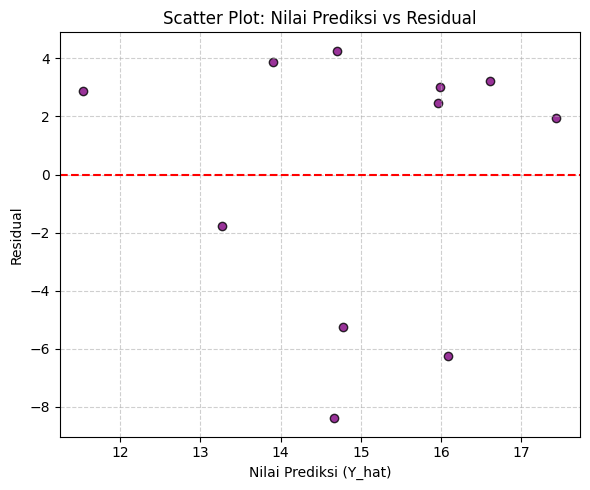

In [ ]:
# ==========================================
# 3. UJI AUTOKORELASI (Durbin-Watson)
# ==========================================
dw_stat = durbin_watson(residual)
print("\n[3] UJI AUTOKORELASI (Durbin-Watson)")
print(f"    - Nilai D-W   : {dw_stat:.4f}")
print("    -> Catatan    : Nilai sekitar 2 umumnya menandakan tidak ada autokorelasi.")

# 3. Scatter Plot Residual vs Predicted (Heteroskedastisitas)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_pred, residual, color='purple', alpha=0.8, edgecolor='k')
ax.axhline(0, color='red', linestyle='--', linewidth=1.5)
ax.set_title("Scatter Plot: Nilai Prediksi vs Residual")
ax.set_xlabel("Nilai Prediksi (Y_hat)")
ax.set_ylabel("Residual")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# Uji Heteroskedastisitas


[4] UJI HETEROSKEDASTISITAS (Breusch-Pagan)
    - P-Value     : 0.4166
    -> Kesimpulan : Tidak terjadi heteroskedastisitas / homoskedastis (Asumsi Terpenuhi)


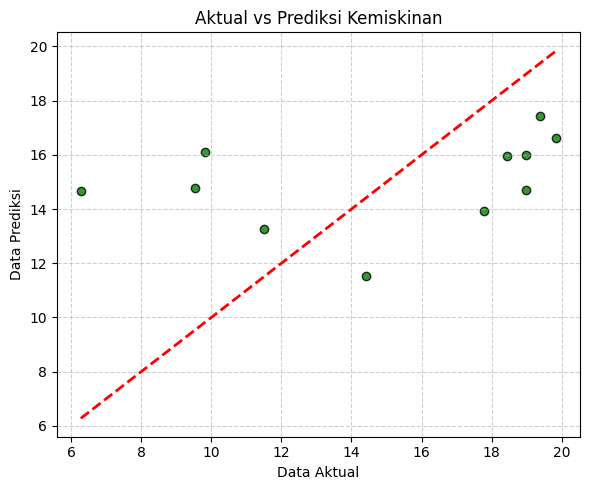

In [ ]:
# ==========================================
# 4. UJI HETEROSKEDASTISITAS (Breusch-Pagan Test)
# ==========================================
bp_test = smd.het_breuschpagan(residual, X_model)
bp_pvalue = bp_test[1]
print("\n[4] UJI HETEROSKEDASTISITAS (Breusch-Pagan)")
print(f"    - P-Value     : {bp_pvalue:.4f}")
if bp_pvalue > 0.05:
    print("    -> Kesimpulan : Tidak terjadi heteroskedastisitas / homoskedastis (Asumsi Terpenuhi)")
else:
    print("    -> Kesimpulan : Terjadi heteroskedastisitas")
print("=" * 70)

# 4. Plot Garis Aktual vs Prediksi
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_clean, y_pred, color='green', alpha=0.8, edgecolor='k')
ax.plot([y_clean.min(), y_clean.max()], [y_clean.min(), y_clean.max()], 'r--', lw=2)
ax.set_title("Aktual vs Prediksi Kemiskinan")
ax.set_xlabel("Data Aktual")
ax.set_ylabel("Data Prediksi")
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()